# micrograd — building backprop from scratch

My notes from Andrej Karpathy's video [The spelled-out intro to neural networks and backpropagation: building micrograd](https://www.youtube.com/watch?v=VMj-3S1tku0).

The flow of this notebook:
1. Derivatives of a simple function, by nudging inputs with a tiny `h`
2. A `Value` class that remembers how every number was computed (a graph)
3. Drawing that graph
4. Backpropagation: pushing gradients from the output back to the inputs
5. A neuron with `tanh`, and checking my answers against PyTorch
6. Neuron → Layer → MLP, a loss, and a training loop (gradient descent)

In [106]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

## 1. What a derivative tells you

Start with a plain function and plot it.

In [107]:
def f(x):
    return 3*x**2-4*x+5

In [108]:
f(3.0)

20.0

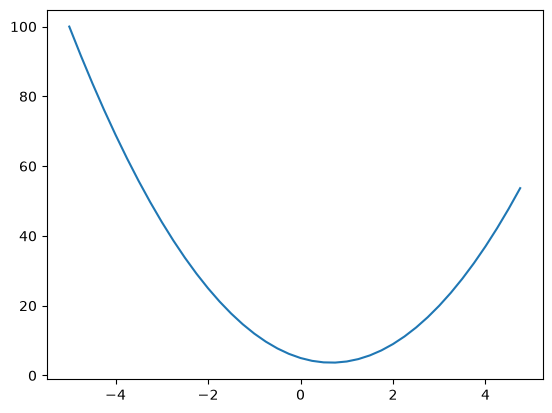

In [109]:
xs=np.arange(-5,5,0.25)
ys=f(xs)
plt.plot(xs,ys)

The derivative is how much the output moves when I nudge the input a tiny bit:

```
slope ≈ (f(x + h) - f(x)) / h
```

- slope **positive** → increasing x increases the output
- slope **negative** → increasing x decreases the output
- slope **0** → x is at a flat spot (here x = 2/3 is the bottom of the curve)

In [110]:
h=0.000000001
x=2/3
(f(x+h)-f(x))/h

0.0

Same idea with several inputs: `d = a*b + c`. Nudge one input at a time and see how much `d` moves. That tells me the **influence** of each input on the output.

In [111]:
a=2.0
b=-3.0
c=10.0
d=a*b+c
print(d)

4.0


Nudging `c` by `h` moves `d` by exactly `h`, so the slope with respect to `c` is 1. (For `a` it would be `b` = -3, and for `b` it would be `a` = 2.)

In [112]:
h=0.0001
#inputs
a=2.0
b=-3.0
c=10.0
d1=a*b+c
c+=h
d2=a*b+c
print('d1',d1)
print('d2',d2)
print('slope',(d2-d1)/h)

d1 4.0
d2 4.0001
slope 0.9999999999976694


## 2. The `Value` class

A `Value` wraps a number and remembers:
- `data` — the number
- `_prev` — the values it was made from (its children)
- `_op` — which operation made it (`+`, `*`, `tanh`...)
- `grad` — how much the final output changes if this value changes (starts at 0)
- `_backward` — a small function that knows how to pass gradient to its children

Every operation (`+`, `*`, `**`, `tanh`, `exp`) creates a new `Value` and sets its `_backward`.

### Backpropagation = chain rule, from the end to the front

Each operation only needs to know its **local** derivative, then multiplies by the gradient coming from above (`out.grad`):

| operation | gradient passed to the inputs |
|---|---|
| `out = a + b` | `a.grad += out.grad`, `b.grad += out.grad` (plus just routes the gradient through) |
| `out = a * b` | `a.grad += b.data * out.grad`, `b.grad += a.data * out.grad` (each gets the *other* value) |
| `out = a ** k` | `a.grad += k * a.data**(k-1) * out.grad` |
| `out = tanh(a)` | `a.grad += (1 - t**2) * out.grad` |
| `out = exp(a)` | `a.grad += out.data * out.grad` |

Why `+=` and not `=`: if a value is used in two places, it gets gradient from both. With `=` the second one would overwrite the first.

### The `backward()` function

1. Set the output's grad to 1 (the output changes 1:1 with itself).
2. **Topological sort** of the graph, so every node comes after the nodes it depends on.
3. Walk that list **in reverse** (output → inputs) and call each node's `_backward`. This way a node's grad is complete before it gets passed further down.

`-`, `/` and `__radd__` / `__rmul__` are built from the others (`a - b = a + (-b)`, `a / b = a * b**-1`), so they get backprop for free.

In [156]:
class Value:
    def __init__(self,data,_children=(),_op='',label=''):
        self.data=data
        self.grad=0.0
        self._backward=lambda: None
        self._prev=set(_children)
        self._op=_op
        self.label=label
    def __repr__(self):
        return f"Value(data={self.data})"
    def __add__(self,other):
        other=other if isinstance(other,Value) else Value(other)
        out=Value(self.data+other.data,(self,other),'+')
        def _backward():
            self.grad+=1.0*out.grad
            other.grad+=1.0*out.grad
        out._backward=_backward
        return out
    def __neg__(self):
        return self*-1
    def __sub__(self,other):
        return self + (-other)
    def __mul__(self,other):
        other=other if isinstance(other,Value) else Value(other)
        out=Value(self.data*other.data,(self,other),'*')
        def _backward():
            self.grad+=out.grad*other.data
            other.grad+=self.data*out.grad

        out._backward=_backward
        return out
    def __radd__(self, other):  # other + self
        return self + other
    def __pow__(self,other):
        assert isinstance(other,(int,float)),"only supporting int/float powers for now"
        out=Value(self.data**other,(self,),f'**{other}')

        def _backward():
            self.grad+=(other*(self.data**(other-1)))*out.grad
        out._backward=_backward
        return out
    def __truediv__(self,other):
        return self*other**-1;
    def __rmul__(self,other):
        return self*other
    def tanh(self):
        n=self.data
        t=(math.exp(2*n)-1)/(math.exp(2*n)+1)
        out=Value(t,(self,),'tanh')
        def _backward():
            self.grad+=(1-t**2)*out.grad

        out._backward=_backward
        return out
    def exp(self):
        x=self.data
        out=Value(math.exp(x),(self,),'exp')
        def _backward():
            self.grad+=out.data*out.grad
        out._backward=_backward
        return out
    def backward(self):
        self.grad=1.0
        topo=[]
        visited=set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)
        for node in reversed(topo):
            node._backward()
        
    
# a=Value(2.0,label='a')
# b=Value(-3.0,label='b')
# c=Value(10.0,label='c')
# e=a*b;e.label='e'
# d=e+c;d.label='d'
# f=Value(-2.0,label='f')
# L=d*f;
# L.label='L'
# print(d)

## 3. Drawing the graph

`trace` collects all nodes and edges; `draw_dot` draws each value as a box (label | data | grad) with a small circle for the operation that produced it. Needs `graphviz` installed.

In [157]:
from graphviz import Digraph

def trace(root):
  # builds a set of all nodes and edges in a graph
  nodes, edges = set(), set()
  def build(v):
    if v not in nodes:
      nodes.add(v)
      for child in v._prev:
        edges.add((child, v))
        build(child)
  build(root)
  return nodes, edges

def draw_dot(root):
  dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right
  
  nodes, edges = trace(root)
  for n in nodes:
    uid = str(id(n))
    # for any value in the graph, create a rectangular ('record') node for it
    dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f }" % (n.label,n.data,n.grad), shape='record')
    if n._op:
      # if this value is a result of some operation, create an op node for it
      dot.node(name = uid + n._op, label = n._op)
      # and connect this node to it
      dot.edge(uid + n._op, uid)

  for n1, n2 in edges:
    # connect n1 to the op node of n2
    dot.edge(str(id(n1)), str(id(n2)) + n2._op)

  return dot

## 4. A single neuron with `tanh`

`o = tanh(x1*w1 + x2*w2 + b)`

Things to notice in the graph after `o.backward()`:
- `n` has grad 0.5 because `1 - tanh(n)^2 = 1 - 0.7071^2 = 0.5`
- the `+` nodes pass 0.5 straight through to `b`, `x1*w1`, `x2*w2`
- `w2.grad = 0` because `x2 = 0`: the weight has no effect when its input is zero

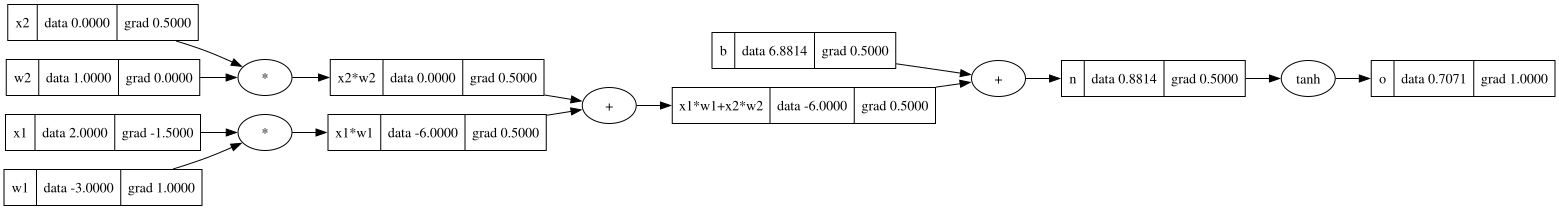

In [158]:
#inputs
x1=Value(2.0,label='x1')
x2=Value(0.0,label='x2')
#weights
w1=Value(-3.0,label='w1')
w2=Value(1.0,label='w2')
#bias
b=Value(6.88137358,label='b')

x1w1=x1*w1;x1w1.label='x1*w1'
x2w2=x2*w2;x2w2.label='x2*w2'
x1w1x2w2=x1w1+x2w2;x1w1x2w2.label='x1*w1+x2*w2'
n=x1w1x2w2+b;n.label='n'
o=n.tanh();o.label='o';
o.backward()
draw_dot(o)

Checking division: `c = a / b` is really `a * b**-1`, and the gradients come out right (`dc/da = 1/b = 0.25`, `dc/db = -a/b² = -0.125`).

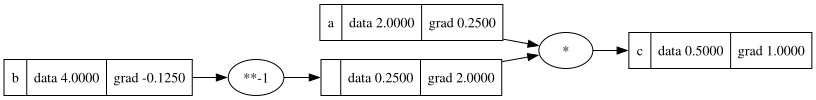

In [159]:
a=Value(2.0,label='a')
b=Value(4.0,label='b')
c=a/b;c.label='c';
c.grad=1.0
c.backward()
draw_dot(c)


Same neuron, but `tanh` written out with `exp`:

```
tanh(n) = (e^(2n) - 1) / (e^(2n) + 1)
```

The output and gradients match the version above. So the level of detail of an operation doesn't matter — as long as I know the local derivative, I can make it one node or break it into many.

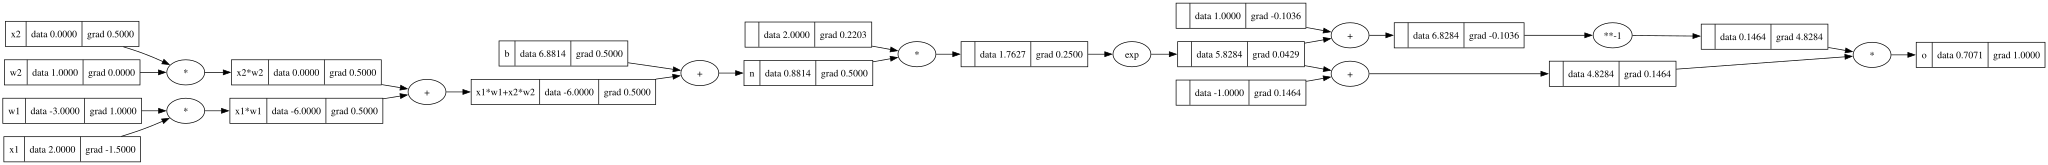

In [160]:
#inputs
x1=Value(2.0,label='x1')
x2=Value(0.0,label='x2')
#weights
w1=Value(-3.0,label='w1')
w2=Value(1.0,label='w2')
#bias
b=Value(6.88137358,label='b')

x1w1=x1*w1;x1w1.label='x1*w1'
x2w2=x2*w2;x2w2.label='x2*w2'
x1w1x2w2=x1w1+x2w2;x1w1x2w2.label='x1*w1+x2*w2'
n=x1w1x2w2+b;n.label='n'
e=(2*n).exp()
o=(e-1)/(e+1)
o.label='o'

o.backward()
draw_dot(o)

## 5. Checking against PyTorch

PyTorch does the same thing with tensors. Same neuron, same numbers → same gradients as my `Value` version. (Use `.double()` so it's float64 like Python floats.)

In [161]:
import torch
import random

In [162]:
x1=torch.Tensor([2.0]).double() ; x1.requires_grad=True
x2=torch.Tensor([0.0]).double() ; x2.requires_grad=True
w1=torch.Tensor([-3.0]).double() ; w1.requires_grad=True
w2=torch.Tensor([1.0]).double() ; w2.requires_grad=True
b=torch.Tensor([6.88137358]).double(); b.requires_grad=True
n=x1*w1+x2*w2+b
o=torch.tanh(n)
print(o.data.item())
o.backward()
print('---')
print('x1',x1.grad.item())
print('x2',x2.grad.item())
print('w1',w1.grad.item())
print('w2',w2.grad.item())




0.7071066904050358
---
x1 -1.5000003851533106
x2 0.5000001283844369
w1 1.0000002567688737
w2 0.0


## 6. Neuron → Layer → MLP

![Neuron model from CS231n](https://cs231n.github.io/assets/nn1/neuron_model.jpeg)

*The neuron diagram Andrej shows in the video, from Stanford CS231n notes ([source](https://cs231n.github.io/neural-networks-1/)).*

- **Neuron**: each input is multiplied by its weight, add the bias, then pass through the activation function (`tanh`). Weights and bias start random in [-1, 1].
- **Layer**: a list of independent neurons that all see the same inputs.
- **MLP** (multi-layer perceptron): layers in a row, each layer's outputs are the next layer's inputs. `MLP(3, [4, 4, 1])` = 3 inputs → 4 neurons → 4 neurons → 1 output.
- `parameters()` collects every weight and bias so we can update them.

In [172]:
class Neuron:
    def __init__(self,nin):
        self.w= [Value(random.uniform(-1,1)) for _ in range(nin)]
        self.b=Value(random.uniform(-1,1))
    def __call__(self,x):
        act = sum((wi*xi for wi, xi in zip(self.w, x)), self.b)
        out=act.tanh()
        return out
    def parameters(self):
        return self.w+[self.b]
class Layer:
    def __init__(self,nin,nout):
        self.neurons=[Neuron(nin) for _ in range(nout)]
    def __call__(self,x):
        outs=[n(x) for n in self.neurons]
        return outs[0] if len(outs)==1 else outs
    def parameters(self):
        params=[]
        for neuron in self.neurons:
            ps=neuron.parameters()
            params.extend(ps)
        return params
class MLP:
    def __init__(self,nin,nouts):
        sz=[nin]+nouts
        self.layers=[Layer(sz[i],sz[i+1]) for i in range(len(nouts))]
    def __call__(self,x):
        for layer in self.layers:
            x=layer(x)
        return x
    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]
x=[2.0,3.0,-1.0]
n=MLP(3,[4,4,1]) #3 inputs -> (4->4->1) layers
n(x)

Value(data=-0.6105138659646884)

## 7. Data and loss

4 examples with 3 inputs each, and the target I want the net to output for each.

**Loss** = how wrong the net is, as one number:

```
loss = sum((prediction - target)^2)
```

Squaring makes every error positive and punishes big errors more. Loss 0 = perfect.

In [238]:
xs=[
    [2.0,3.0,-1.0],
    [3.0,-1.0,1.5],
    [0.5,1.0,1.0],
    [4.0,1.0,-1.0],
]
ys=[2.0,-5.0,-1.0,4.0] # desired targets



## 8. Training loop (gradient descent)

Each iteration:
1. **Forward pass** — run all inputs through the net, compute the loss.
2. **Zero the grads** — because `_backward` uses `+=`, old gradients would pile up otherwise.
3. **Backward pass** — `loss.backward()` fills `.grad` for every weight and bias.
4. **Update** — `p.data += -learning_rate * p.grad`

Why the minus sign: `grad` points in the direction that **increases** the loss. We want the loss to go **down**, so we step the opposite way. If grad is negative, increasing the weight lowers the loss, and `-lr * grad` is positive, so it increases. Learning rate (0.05) = step size: too big and it overshoots, too small and it's slow.

⚠️ **Why the loss is stuck at 26.0 here:** `tanh` only outputs between -1 and 1, but my targets are `[2, -5, -1, 4]`. The net can never reach them, so it pushes every output to ±1, where `tanh` is flat and its gradient `1 - t²` is ~0. No gradient → no learning. The loss works out to (1-2)² + (-1+5)² + (-1+1)² + (1-4)² = 1 + 16 + 0 + 9 = 26. Fix: use targets inside (-1, 1), like the video's `[1.0, -1.0, -1.0, 1.0]`, and re-create the MLP.

In [239]:
for k in range(20):
    #forward pass
    ypred=[n(x) for x in xs]
    loss=sum((yout-ygt)**2 for ygt,yout in zip(ys,ypred))
    #backward pass
    for p in n.parameters():
        p.grad=0.0
    loss.backward()
    #update
    for p in n.parameters():
        p.data+=-0.05*p.grad
    print(k,loss.data)

0 26.0
1 26.0
2 26.0
3 26.0
4 26.0
5 26.0
6 26.0
7 26.0
8 26.0
9 26.0
10 26.0
11 26.0
12 26.0
13 26.0
14 26.0
15 26.0
16 26.0
17 26.0
18 26.0
19 26.0


### The single manual steps (I did these before writing the loop)

Below is the same process done by hand, one step at a time: compute loss → backward → look at one weight's grad → nudge all parameters → recompute predictions and see the loss drop.

In [174]:
loss=sum(([(yout-ygt)**2 for ygt,yout in zip(ys,ypred)]))
loss

Value(data=6.1315469037287285)

In [219]:
ypred=[n(x) for x in xs]
loss=sum(([(yout-ygt)**2 for ygt,yout in zip(ys,ypred)]))
loss

Value(data=4.894088704980138)

In [175]:
loss.backward()


Reading one gradient: this weight's grad is negative, so increasing it would decrease the loss.

In [176]:
n.layers[0].neurons[0].w[0].grad #increasing the value decreases the loss grad is neg

-0.8692379795446589

In [177]:
n.layers[0].neurons[0].w[0].data

-0.5026256539905074

In [218]:
for p in n.parameters():
    p.data+=-0.01*p.grad

In [205]:
ypred

[Value(data=0.5545922012395866),
 Value(data=-0.7228754061831912),
 Value(data=0.45831469811166975),
 Value(data=0.4090900403180171)]